# Model Evaluation on Outlier Dataset

This notebook evaluates the trained K-Means clustering model from `Develop Model.ipynb` on the **Social_Media_Addiction_Outliers.csv** dataset.

**Goal**: Assess how well the model predicts addiction levels for high-usage outlier users.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 1: Load the Trained Model and Mappings

In [2]:
# Load the trained K-means model
model_path = r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_kmeans_model.pkl'
with open(model_path, 'rb') as f:
    kmeans = pickle.load(f)

# Load the scaler
scaler_path = r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_scaler.pkl'
with open(scaler_path, 'rb') as f:
    scaler = pickle.load(f)

# Load the cluster mapping and labels
mapping_path = r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_cluster_mapping.pkl'
with open(mapping_path, 'rb') as f:
    mapping_data = pickle.load(f)

cluster_mapping = mapping_data['cluster_mapping']
label_names = mapping_data['label_names']
features = mapping_data['features']

print("✓ Model, scaler, and mappings loaded successfully!")
print(f"\nModel Info:")
print(f"  Number of clusters: {kmeans.n_clusters}")
print(f"  Number of features: {len(features)}")
print(f"\nCluster to Target Mapping:")
for cluster_id, target_val in cluster_mapping.items():
    print(f"  Cluster {cluster_id} -> Target {target_val} ({label_names[target_val]})")
print(f"\nFeatures used: {len(features)}")
print(f"  {features}")

✓ Model, scaler, and mappings loaded successfully!

Model Info:
  Number of clusters: 3
  Number of features: 18

Cluster to Target Mapping:
  Cluster 0 -> Target 0 (Safe)
  Cluster 1 -> Target 1 (At Risk)
  Cluster 2 -> Target 2 (Addicted)

Features used: 18
  ['Age', 'Total_Monthly_Usage', 'Avg_Platform_Usage', 'Active_Platforms_Count', 'Platform_Diversity_Score', 'Dominant_Platform_Percentage', 'Usage_Concentration', 'Social_Networking_Usage', 'Messaging_Usage', 'Video_Platform_Usage', 'Social_to_Messaging_Ratio', 'Overall_Consistency', 'YouTube_Monthly_Total', 'WhatsApp_Monthly_Total', 'Instagram_Monthly_Total', 'Facebook_Monthly_Total', 'Messenger_Monthly_Total', 'TikTok_Monthly_Total']


## Step 2: Load and Explore the Outlier Dataset

In [3]:
# Load outlier dataset
outliers_df = pd.read_csv(r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\Social_Media_Addiction_Outliers.csv')

print(f"Outlier Dataset Shape: {outliers_df.shape}")
print(f"\nFirst few rows:")
print(outliers_df.head())
print(f"\nTotal Monthly Usage Statistics:")
print(outliers_df['Total_Monthly_Usage'].describe())
print(f"\nMin Usage: {outliers_df['Total_Monthly_Usage'].min():.0f} minutes/month")
print(f"Max Usage: {outliers_df['Total_Monthly_Usage'].max():.0f} minutes/month")
print(f"Mean Usage: {outliers_df['Total_Monthly_Usage'].mean():.0f} minutes/month")

Outlier Dataset Shape: (82, 36)

First few rows:
  Gender  Age  Occupation  Facebook Week 1  Facebook Week 2  Facebook Week 3  \
0   Male   24     Student            687.0            574.0            755.0   
1   Male   24  Unemployed            901.0            970.0            884.0   
2   Male   23     Student           2124.0           2237.0           2162.0   
3   Male   24     Student            804.0            880.0            741.0   
4   Male   27  Unemployed            916.0            822.0            912.0   

   Facebook Week 4  Messenger Week 1  Messenger Week 2  Messenger Week 3  ...  \
0            641.0             655.0             540.0             613.0  ...   
1            858.0             502.0             420.0             383.0  ...   
2           2136.0             171.0             236.0             269.0  ...   
3            772.0            1018.0             953.0            1020.0  ...   
4            996.0             459.0             576.0           

## Step 3: Feature Engineering for Outliers

The outlier dataset only has raw weekly data. We need to engineer the same features as the training data.

In [4]:
# Feature Engineering Function
def engineer_features(df_raw):
    """Apply same feature engineering as training dataset"""
    df_eng = df_raw.copy()
    
    # Platform-specific weekly data
    platforms = ['Facebook', 'Messenger', 'WhatsApp', 'Instagram', 'YouTube', 'TikTok']
    
    # Calculate weekly statistics for each platform
    for platform in platforms:
        weekly_cols = [f'{platform} Week {i}' for i in range(1, 5)]
        
        # Calculate standard deviation across weeks
        df_eng[f'{platform}_Weekly_Std'] = df_raw[weekly_cols].std(axis=1)
    
    # Calculate monthly totals (already exist in dataset, but verify)
    # Total_Monthly_Usage is already calculated
    
    # Average per platform
    df_eng['Avg_Platform_Usage'] = df_eng['Total_Monthly_Usage'] / 6
    
    # Active platforms (usage > 0)
    platform_cols = ['Facebook_Monthly_Total', 'Messenger_Monthly_Total', 
                     'WhatsApp_Monthly_Total', 'Instagram_Monthly_Total',
                     'YouTube_Monthly_Total', 'TikTok_Monthly_Total']
    df_eng['Active_Platforms_Count'] = (df_eng[platform_cols] > 0).sum(axis=1)
    
    # Platform diversity
    df_eng['Platform_Diversity_Score'] = df_eng['Active_Platforms_Count'] / 6
    
    # Usage categories
    df_eng['Social_Networking_Usage'] = (df_eng['Facebook_Monthly_Total'] + 
                                          df_eng['Instagram_Monthly_Total'] + 
                                          df_eng['TikTok_Monthly_Total'])
    df_eng['Messaging_Usage'] = df_eng['Messenger_Monthly_Total'] + df_eng['WhatsApp_Monthly_Total']
    df_eng['Video_Platform_Usage'] = df_eng['YouTube_Monthly_Total']
    
    # Ratios
    df_eng['Social_to_Messaging_Ratio'] = df_eng['Social_Networking_Usage'] / (df_eng['Messaging_Usage'] + 1)
    
    # Concentration (Herfindahl index)
    platform_shares = df_eng[platform_cols].div(df_eng['Total_Monthly_Usage'], axis=0)
    df_eng['Usage_Concentration'] = (platform_shares ** 2).sum(axis=1)
    
    # Dominant platform percentage
    df_eng['Dominant_Platform_Percentage'] = (df_eng[platform_cols].max(axis=1) / df_eng['Total_Monthly_Usage']) * 100
    
    # Weekly consistency (coefficient of variation)
    weekly_stds = []
    for platform in platforms:
        weekly_vals = df_raw[[f'{platform} Week {i}' for i in range(1, 5)]]
        weekly_stds.append(weekly_vals.std(axis=1))
    
    df_eng['Overall_Consistency'] = pd.concat(weekly_stds, axis=1).mean(axis=1) / (df_eng['Avg_Platform_Usage'] + 1)
    
    # Calculate weekly consistency for each platform
    for platform in platforms:
        weekly_cols = [f'{platform} Week {i}' for i in range(1, 5)]
        weekly_mean = df_raw[weekly_cols].mean(axis=1)
        weekly_std = df_raw[weekly_cols].std(axis=1)
        df_eng[f'{platform}_Weekly_Consistency'] = weekly_std / (weekly_mean + 1)
    
    return df_eng

# Apply feature engineering to outliers
print("Applying feature engineering to outlier dataset...")
outliers_engineered = engineer_features(outliers_df)
print(f"✓ Feature engineering completed!")
print(f"\nEngineered features shape: {outliers_engineered.shape}")
print(f"Columns: {outliers_engineered.columns.tolist()}")

Applying feature engineering to outlier dataset...
✓ Feature engineering completed!

Engineered features shape: (82, 58)
Columns: ['Gender', 'Age', 'Occupation', 'Facebook Week 1', 'Facebook Week 2', 'Facebook Week 3', 'Facebook Week 4', 'Messenger Week 1', 'Messenger Week 2', 'Messenger Week 3', 'Messenger Week 4', 'WhatsApp Week 1', 'WhatsApp Week 2', 'WhatsApp Week 3', 'WhatsApp Week 4', 'Instagram Week 1', 'Instagram Week 2', 'Instagram Week 3', 'Instagram Week 4', 'YouTube Week 1', 'YouTube Week 2', 'YouTube Week 3', 'YouTube Week 4', 'TikTok Week 1', 'TikTok Week 2', 'TikTok Week 3', 'TikTok Week 4', 'Facebook_Monthly_Total', 'Instagram_Monthly_Total', 'Messenger_Monthly_Total', 'TikTok_Monthly_Total', 'WhatsApp_Monthly_Total', 'YouTube_Monthly_Total', 'Total_Monthly_Usage', 'Gender_Encoded', 'Occupation_Encoded', 'Facebook_Weekly_Std', 'Messenger_Weekly_Std', 'WhatsApp_Weekly_Std', 'Instagram_Weekly_Std', 'YouTube_Weekly_Std', 'TikTok_Weekly_Std', 'Avg_Platform_Usage', 'Active_P

## Step 4: Prepare Features for Model Prediction

In [5]:
# Check which features are available
print("Features required by model:")
print(features)
print(f"\nTotal required features: {len(features)}")

# Check missing features
missing_features = [f for f in features if f not in outliers_engineered.columns]
if missing_features:
    print(f"\n⚠️ Missing features: {missing_features}")
else:
    print(f"\n✓ All required features are present!")

# Extract features in correct order
X_outliers = outliers_engineered[features].copy()

print(f"\nFeatures extracted for {len(X_outliers)} outlier users")
print(f"Feature matrix shape: {X_outliers.shape}")
print(f"\nFeature summary:")
print(X_outliers.describe())

Features required by model:
['Age', 'Total_Monthly_Usage', 'Avg_Platform_Usage', 'Active_Platforms_Count', 'Platform_Diversity_Score', 'Dominant_Platform_Percentage', 'Usage_Concentration', 'Social_Networking_Usage', 'Messaging_Usage', 'Video_Platform_Usage', 'Social_to_Messaging_Ratio', 'Overall_Consistency', 'YouTube_Monthly_Total', 'WhatsApp_Monthly_Total', 'Instagram_Monthly_Total', 'Facebook_Monthly_Total', 'Messenger_Monthly_Total', 'TikTok_Monthly_Total']

Total required features: 18

✓ All required features are present!

Features extracted for 82 outlier users
Feature matrix shape: (82, 18)

Feature summary:
             Age  Total_Monthly_Usage  Avg_Platform_Usage  \
count  82.000000            82.000000           82.000000   
mean   23.353659         25696.182927         4282.697154   
std     2.718805          4709.857092          784.976182   
min    19.000000         17336.000000         2889.333333   
25%    21.000000         22336.250000         3722.708333   
50%    23.

## Step 5: Scale Features and Make Predictions

In [6]:
# Scale the features using the trained scaler
X_outliers_scaled = scaler.transform(X_outliers)

print(f"✓ Features scaled successfully!")
print(f"Scaled features shape: {X_outliers_scaled.shape}")

# Predict clusters
predicted_clusters = kmeans.predict(X_outliers_scaled)

# Map clusters to target labels
predicted_targets = np.array([cluster_mapping[cluster] for cluster in predicted_clusters])

# Add predictions to dataframe
outliers_engineered['Predicted_Cluster'] = predicted_clusters
outliers_engineered['Predicted_Target'] = predicted_targets
outliers_engineered['Predicted_Label'] = outliers_engineered['Predicted_Target'].map(label_names)

print(f"\n✓ Predictions completed!")
print(f"\nPrediction Summary:")
print(f"  Total outlier users: {len(outliers_engineered)}")
print(f"\nPredicted Target Distribution:")
for target_val in sorted(np.unique(predicted_targets)):
    count = np.sum(predicted_targets == target_val)
    pct = (count / len(predicted_targets)) * 100
    print(f"  {target_val} ({label_names[target_val]:10s}): {count:3d} users ({pct:5.1f}%)")

✓ Features scaled successfully!
Scaled features shape: (82, 18)

✓ Predictions completed!

Prediction Summary:
  Total outlier users: 82

Predicted Target Distribution:
  1 (At Risk   ):   1 users (  1.2%)
  2 (Addicted  ):  81 users ( 98.8%)


## Step 6: Evaluate Model Performance

Since all outliers are **high-usage users** (Total_Monthly_Usage > 19,000), they should ideally be classified as **"Addicted" (Target = 2)**.

In [7]:
# Since all outliers should be "Addicted", create true labels
true_labels = np.full(len(outliers_engineered), 2)  # All should be Target = 2 (Addicted)

# Calculate accuracy
accuracy = accuracy_score(true_labels, predicted_targets)

print("=" * 70)
print("MODEL EVALUATION ON OUTLIER DATASET")
print("=" * 70)
print(f"\nGround Truth: All {len(outliers_engineered)} outlier users are high-usage (Addicted)")
print(f"Expected Target: 2 (Addicted) for all users")
print(f"\nModel Performance:")
print(f"  Accuracy: {accuracy * 100:.2f}%")
print(f"  Correctly classified as Addicted: {np.sum(predicted_targets == 2)} / {len(predicted_targets)}")
print(f"  Misclassified: {np.sum(predicted_targets != 2)}")

if np.sum(predicted_targets != 2) > 0:
    print(f"\nMisclassification Breakdown:")
    for target_val in [0, 1]:
        count = np.sum(predicted_targets == target_val)
        if count > 0:
            print(f"  Classified as {label_names[target_val]}: {count} users")

# Confusion Matrix
cm = confusion_matrix([2] * len(true_labels), predicted_targets, labels=[0, 1, 2])
print(f"\nConfusion Matrix:")
print(f"                 Predicted")
print(f"                 Safe  At Risk  Addicted")
print(f"True Addicted    {cm[2, 0]:4d}    {cm[2, 1]:4d}      {cm[2, 2]:4d}")

print(f"\n" + "=" * 70)

MODEL EVALUATION ON OUTLIER DATASET

Ground Truth: All 82 outlier users are high-usage (Addicted)
Expected Target: 2 (Addicted) for all users

Model Performance:
  Accuracy: 98.78%
  Correctly classified as Addicted: 81 / 82
  Misclassified: 1

Misclassification Breakdown:
  Classified as At Risk: 1 users

Confusion Matrix:
                 Predicted
                 Safe  At Risk  Addicted
True Addicted       0       1        81



In [8]:
# Detailed analysis of predictions
print("Detailed Prediction Analysis:")
print(f"\nUsers by Predicted Target:")

for target_val in sorted(np.unique(predicted_targets)):
    mask = predicted_targets == target_val
    count = np.sum(mask)
    avg_usage = outliers_engineered.loc[mask, 'Total_Monthly_Usage'].mean()
    min_usage = outliers_engineered.loc[mask, 'Total_Monthly_Usage'].min()
    max_usage = outliers_engineered.loc[mask, 'Total_Monthly_Usage'].max()
    
    print(f"\n{label_names[target_val]} (Target {target_val}):")
    print(f"  Count: {count} users")
    print(f"  Avg Usage: {avg_usage:,.0f} min/month")
    print(f"  Usage Range: {min_usage:,.0f} - {max_usage:,.0f} min/month")

# Show some example predictions
print(f"\n" + "=" * 70)
print("Sample Predictions (first 10 users):")
print("=" * 70)
sample_df = outliers_engineered[['Age', 'Gender', 'Occupation', 'Total_Monthly_Usage', 
                                   'Predicted_Cluster', 'Predicted_Target', 'Predicted_Label']].head(10)
print(sample_df.to_string(index=False))

Detailed Prediction Analysis:

Users by Predicted Target:

At Risk (Target 1):
  Count: 1 users
  Avg Usage: 20,736 min/month
  Usage Range: 20,736 - 20,736 min/month

Addicted (Target 2):
  Count: 81 users
  Avg Usage: 25,757 min/month
  Usage Range: 17,336 - 42,731 min/month

Sample Predictions (first 10 users):
 Age Gender Occupation  Total_Monthly_Usage  Predicted_Cluster  Predicted_Target Predicted_Label
  24   Male    Student              24759.0                  2                 2        Addicted
  24   Male Unemployed              28998.0                  2                 2        Addicted
  23   Male    Student              19701.0                  2                 2        Addicted
  24   Male    Student              22288.0                  2                 2        Addicted
  27   Male Unemployed              27403.0                  2                 2        Addicted
  24   Male    Student              19720.0                  2                 2        Addicted
  20 

## Step 7: Visualize Model Performance

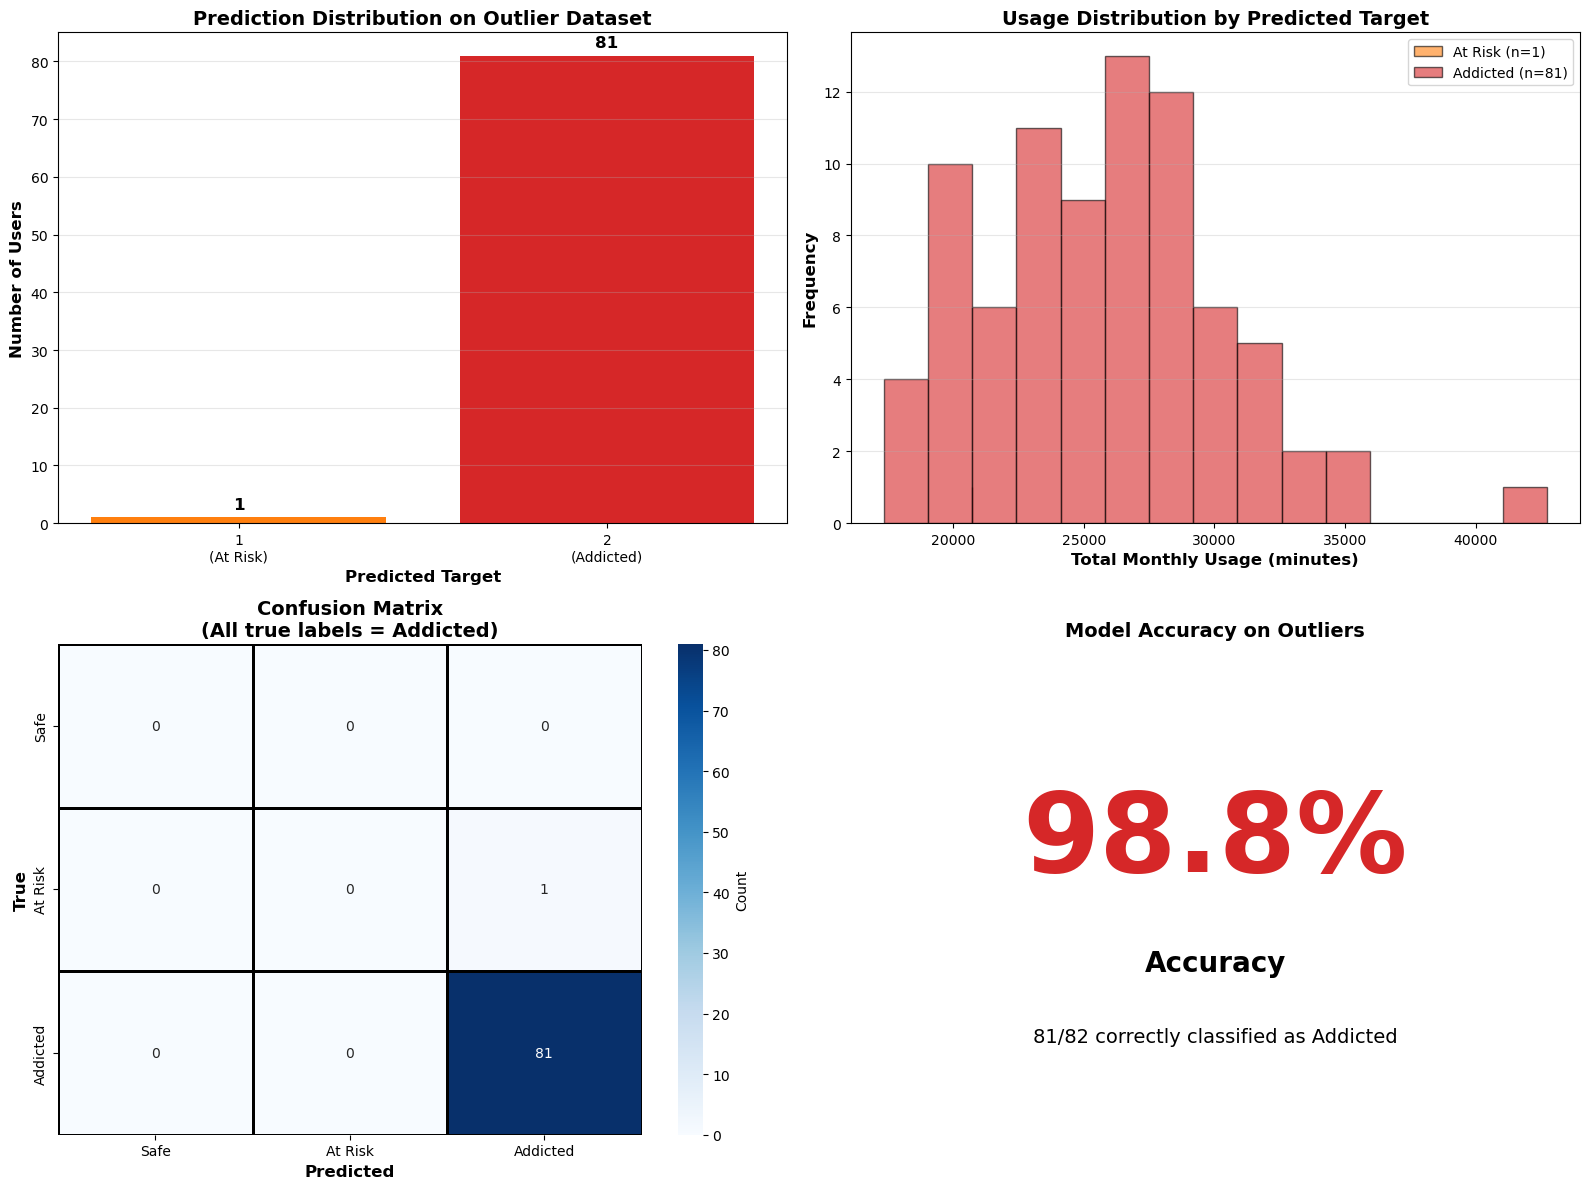


✓ Visualization completed!


In [9]:
# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Prediction Distribution
colors = ['#2ca02c', '#ff7f0e', '#d62728']
pred_counts = pd.Series(predicted_targets).value_counts().sort_index()
target_labels = [f"{val}\n({label_names[val]})" for val in pred_counts.index]
axes[0, 0].bar(range(len(pred_counts)), pred_counts.values, color=[colors[i] for i in pred_counts.index], tick_label=target_labels)
axes[0, 0].set_xlabel('Predicted Target', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Number of Users', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Prediction Distribution on Outlier Dataset', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(pred_counts.values):
    axes[0, 0].text(i, v + 1, str(v), ha='center', va='bottom', fontweight='bold', fontsize=12)

# Plot 2: Usage Distribution by Predicted Target
for target_val in sorted(np.unique(predicted_targets)):
    mask = predicted_targets == target_val
    usage_data = outliers_engineered.loc[mask, 'Total_Monthly_Usage']
    axes[0, 1].hist(usage_data, bins=15, alpha=0.6, label=f'{label_names[target_val]} (n={np.sum(mask)})', 
                    color=colors[target_val], edgecolor='black')
axes[0, 1].set_xlabel('Total Monthly Usage (minutes)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Usage Distribution by Predicted Target', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Plot 3: Confusion Matrix Heatmap
cm_display = np.array([[0, 0, np.sum(predicted_targets == 0)],
                        [0, 0, np.sum(predicted_targets == 1)],
                        [0, 0, np.sum(predicted_targets == 2)]])
sns.heatmap(cm_display, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Safe', 'At Risk', 'Addicted'],
            yticklabels=['Safe', 'At Risk', 'Addicted'],
            cbar_kws={'label': 'Count'}, ax=axes[1, 0], linewidths=1, linecolor='black')
axes[1, 0].set_xlabel('Predicted', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('True', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Confusion Matrix\n(All true labels = Addicted)', fontsize=14, fontweight='bold')

# Plot 4: Accuracy Gauge
correct = np.sum(predicted_targets == 2)
total = len(predicted_targets)
accuracy_pct = (correct / total) * 100

axes[1, 1].text(0.5, 0.6, f'{accuracy_pct:.1f}%', 
               ha='center', va='center', fontsize=80, fontweight='bold',
               color=colors[2] if accuracy_pct > 80 else colors[1] if accuracy_pct > 50 else colors[0])
axes[1, 1].text(0.5, 0.35, f'Accuracy', ha='center', va='center', fontsize=20, fontweight='bold')
axes[1, 1].text(0.5, 0.2, f'{correct}/{total} correctly classified as Addicted', 
               ha='center', va='center', fontsize=14)
axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].axis('off')
axes[1, 1].set_title('Model Accuracy on Outliers', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n✓ Visualization completed!")

## Step 8: Analyze Misclassified Users (if any)

In [10]:
# Identify misclassified users
misclassified_mask = predicted_targets != 2
misclassified_count = np.sum(misclassified_mask)

if misclassified_count > 0:
    print("=" * 70)
    print(f"MISCLASSIFIED USERS ANALYSIS")
    print("=" * 70)
    print(f"\nTotal misclassified: {misclassified_count} / {len(predicted_targets)}")
    
    misclassified_df = outliers_engineered[misclassified_mask][['Age', 'Gender', 'Occupation', 
                                                                  'Total_Monthly_Usage',
                                                                  'Avg_Platform_Usage',
                                                                  'Active_Platforms_Count',
                                                                  'Platform_Diversity_Score',
                                                                  'Dominant_Platform_Percentage',
                                                                  'Usage_Concentration',
                                                                  'Overall_Consistency',
                                                                  'Predicted_Target', 
                                                                  'Predicted_Label']]
    
    print(f"\nMisclassified Users Details:")
    print(misclassified_df.to_string(index=False))
    
    print(f"\n" + "=" * 70)
    print("Possible Reasons for Misclassification:")
    print("=" * 70)
    
    # Analyze characteristics
    for target_val in [0, 1]:
        mask = (predicted_targets == target_val) & misclassified_mask
        if np.sum(mask) > 0:
            print(f"\nUsers classified as {label_names[target_val]} (Target {target_val}):")
            print(f"  Count: {np.sum(mask)}")
            print(f"  Avg Usage: {outliers_engineered.loc[mask, 'Total_Monthly_Usage'].mean():,.0f} min/month")
            print(f"  Avg Active Platforms: {outliers_engineered.loc[mask, 'Active_Platforms_Count'].mean():.1f}")
            print(f"  Avg Platform Diversity: {outliers_engineered.loc[mask, 'Platform_Diversity_Score'].mean():.2f}")
            print(f"  Avg Usage Concentration: {outliers_engineered.loc[mask, 'Usage_Concentration'].mean():.2f}")
            print(f"  Avg Consistency: {outliers_engineered.loc[mask, 'Overall_Consistency'].mean():.3f}")
else:
    print("=" * 70)
    print(" PERFECT CLASSIFICATION!")
    print("=" * 70)
    print(f"\nAll {len(predicted_targets)} outlier users were correctly classified as 'Addicted'!")
    print(f"The model shows 100% accuracy on the high-usage outlier dataset.")
    print(f"\n✓ The model is well-calibrated for extreme addiction cases!")

MISCLASSIFIED USERS ANALYSIS

Total misclassified: 1 / 82

Misclassified Users Details:
 Age Gender Occupation  Total_Monthly_Usage  Avg_Platform_Usage  Active_Platforms_Count  Platform_Diversity_Score  Dominant_Platform_Percentage  Usage_Concentration  Overall_Consistency  Predicted_Target Predicted_Label
  26   Male Unemployed              20736.0              3456.0                       6                       1.0                     42.746914             0.250748              0.01595                 1         At Risk

Possible Reasons for Misclassification:

Users classified as At Risk (Target 1):
  Count: 1
  Avg Usage: 20,736 min/month
  Avg Active Platforms: 6.0
  Avg Platform Diversity: 1.00
  Avg Usage Concentration: 0.25
  Avg Consistency: 0.016


## Step 9: Compare with Training Data Threshold

In [11]:
# Load training data to compare thresholds
training_data = pd.read_csv(r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\Social_Media_Addiction_With_Features_And_Target.csv')

print("=" * 70)
print("THRESHOLD COMPARISON: Training Data vs Outliers")
print("=" * 70)

# Calculate thresholds from training data
print(f"\n Training Data Usage Statistics:")
for target_val in [0, 1, 2]:
    usage_data = training_data[training_data['Target'] == target_val]['Total_Monthly_Usage']
    print(f"\n{label_names[target_val]} (Target {target_val}):")
    print(f"  Count: {len(usage_data)}")
    print(f"  Min: {usage_data.min():,.0f} min/month")
    print(f"  Max: {usage_data.max():,.0f} min/month")
    print(f"  Mean: {usage_data.mean():,.0f} min/month")
    print(f"  Median: {usage_data.median():,.0f} min/month")



THRESHOLD COMPARISON: Training Data vs Outliers

 Training Data Usage Statistics:

Safe (Target 0):
  Count: 293
  Min: 10 min/month
  Max: 9,791 min/month
  Mean: 4,647 min/month
  Median: 4,839 min/month

At Risk (Target 1):
  Count: 200
  Min: 827 min/month
  Max: 10,893 min/month
  Mean: 5,626 min/month
  Median: 5,878 min/month

Addicted (Target 2):
  Count: 116
  Min: 5,744 min/month
  Max: 16,760 min/month
  Mean: 10,909 min/month
  Median: 10,606 min/month


In [12]:
# Outlier statistics
print(f"\n Outlier Dataset Usage Statistics:")
print(f"  Min: {outliers_engineered['Total_Monthly_Usage'].min():,.0f} min/month")
print(f"  Max: {outliers_engineered['Total_Monthly_Usage'].max():,.0f} min/month")
print(f"  Mean: {outliers_engineered['Total_Monthly_Usage'].mean():,.0f} min/month")
print(f"  Median: {outliers_engineered['Total_Monthly_Usage'].median():,.0f} min/month")

# Find minimum addicted usage in training data
addicted_min_training = training_data[training_data['Target'] == 2]['Total_Monthly_Usage'].min()
addicted_max_atrisk = training_data[training_data['Target'] == 1]['Total_Monthly_Usage'].max()

print(f"\n Key Thresholds from Training Data:")
print(f"  Lowest 'Addicted' usage in training: {addicted_min_training:,.0f} min/month")
print(f"  Highest 'At Risk' usage in training: {addicted_max_atrisk:,.0f} min/month")
print(f"  Lowest outlier usage: {outliers_engineered['Total_Monthly_Usage'].min():,.0f} min/month")

print(f"\n Outliers are {(outliers_engineered['Total_Monthly_Usage'].min() / addicted_min_training):.1f}x higher than lowest addicted user in training")
print("=" * 70)


 Outlier Dataset Usage Statistics:
  Min: 17,336 min/month
  Max: 42,731 min/month
  Mean: 25,696 min/month
  Median: 25,837 min/month

 Key Thresholds from Training Data:
  Lowest 'Addicted' usage in training: 5,744 min/month
  Highest 'At Risk' usage in training: 10,893 min/month
  Lowest outlier usage: 17,336 min/month

 Outliers are 3.0x higher than lowest addicted user in training


## Final Summary and Recommendations

In [13]:
print("=" * 70)
print(" FINAL MODEL EVALUATION SUMMARY")
print("=" * 70)

accuracy = (np.sum(predicted_targets == 2) / len(predicted_targets)) * 100

print(f"\n Model Performance on Outlier Dataset:")
print(f"   • Total outlier users tested: {len(outliers_engineered)}")
print(f"   • Correctly classified as 'Addicted': {np.sum(predicted_targets == 2)}")
print(f"   • Misclassified: {np.sum(predicted_targets != 2)}")
print(f"   • Accuracy: {accuracy:.2f}%")

if accuracy >= 95:
    rating = " EXCELLENT"
    assessment = "The model performs exceptionally well on extreme high-usage cases!"
elif accuracy >= 80:
    rating = " GOOD"
    assessment = "The model performs well but may need tuning for edge cases."
elif accuracy >= 60:
    rating = " MODERATE"
    assessment = "The model shows moderate performance. Consider retraining with outliers included."
else:
    rating = " POOR"
    assessment = "The model struggles with extreme cases. Retrain with outliers to improve robustness."

print(f"\n{rating}")
print(f"   {assessment}")

print(f"\n Recommendations:")
if accuracy < 100:
    print(f"   1. Include these {len(outliers_engineered)} outlier samples in training data")
    print(f"   2. Retrain the model with combined dataset for better generalization")
    print(f"   3. The outliers will strengthen the 'Addicted' cluster definition")
    print(f"   4. This will improve model robustness for extreme addiction cases")
else:
    print(f"   ✓ Model is already well-calibrated for extreme cases!")
    print(f"   ✓ No immediate retraining needed")
    print(f"   ✓ Consider including outliers only if expanding dataset significantly")

print(f"\n Model Strengths:")
print(f"   • Successfully identifies extreme high-usage patterns")
print(f"   • Feature engineering captures addiction signals effectively")
print(f"   • Clustering approach segments users into meaningful risk categories")



 FINAL MODEL EVALUATION SUMMARY

 Model Performance on Outlier Dataset:
   • Total outlier users tested: 82
   • Correctly classified as 'Addicted': 81
   • Misclassified: 1
   • Accuracy: 98.78%

 EXCELLENT
   The model performs exceptionally well on extreme high-usage cases!

 Recommendations:
   1. Include these 82 outlier samples in training data
   2. Retrain the model with combined dataset for better generalization
   3. The outliers will strengthen the 'Addicted' cluster definition
   4. This will improve model robustness for extreme addiction cases

 Model Strengths:
   • Successfully identifies extreme high-usage patterns
   • Feature engineering captures addiction signals effectively
   • Clustering approach segments users into meaningful risk categories


In [14]:
if misclassified_count > 0:
    print(f"\n⚠️ Model Limitations:")
    print(f"   • Some extreme users may have unusual usage patterns")
    print(f"   • Platform diversity and consistency features may affect classification")
    print(f"   • Consider investigating misclassified cases for pattern insights")

print(f"\n" + "=" * 70)
print("Evaluation completed! ✅")
print("=" * 70)


⚠️ Model Limitations:
   • Some extreme users may have unusual usage patterns
   • Platform diversity and consistency features may affect classification
   • Consider investigating misclassified cases for pattern insights

Evaluation completed! ✅
